# Temperature

In [1]:
# check the variables
import xarray as xr
import numpy as np

ds_0 = xr.open_dataset("/Users/dianindrawati/Documents/ERA5_datasets/Temperature/era5_t2m_reg_combined_19712000.nc")
print(ds_0)

<xarray.Dataset> Size: 3GB
Dimensions:     (valid_time: 11323, lon: 360, lat: 181)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 91kB 1970-01-01T11:30:00 ... 2000...
  * lon         (lon) float64 3kB 0.0 1.0 2.0 3.0 ... 356.0 357.0 358.0 359.0
  * lat         (lat) float64 1kB -90.0 -89.0 -88.0 -87.0 ... 88.0 89.0 90.0
Data variables:
    t2m         (valid_time, lat, lon) float32 3GB ...
Attributes:
    CDI:          Climate Data Interface version 2.5.1 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Fri May 23 13:30:44 2025: cdo -f nc mergetime t2m_ERA5_regr...
    CDO:          Climate Data Operators version 2.5.1 (https://mpimet.mpg.de...


/opt/anaconda3/envs/era5/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Annual Land-Only Temperature Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):
Region		Diff (°C)	Change (%)	Std Dev (°C)	Std Dev (%)	Land cells
Global              0.313 °C	    0.11%		   0.324 °C	    0.11%		11751
Tropics             0.270 °C	    0.09%		   0.304 °C	    0.10%		4178
Subtropics_N        0.362 °C	    0.12%		   0.418 °C	    0.14%		1768
Subtropics_S        0.200 °C	    0.07%		   0.289 °C	    0.10%		818
Mid_Latitudes_N     0.385 °C	    0.14%		   0.474 °C	    0.17%		4886
Mid_Latitudes_S     0.110 °C	    0.04%		   0.295 °C	    0.10%		288

Detailed Land-Only Statistics by Period:

Global:
  Baseline (1971-2000): Mean = 16.189 °C, Std Dev = 0.320 °C
  Present  (1981-2010): Mean = 16.503 °C, Std Dev = 0.329 °C

Tropics:
  Baseline (1971-2000): Mean = 24.415 °C, Std Dev = 0.309 °C
  Present  (1981-2010): Mean = 24.685 °C, Std Dev = 0.299 °C

Subtropics_N:
  Baseline (1971-2000): Mean = 17.471 °C, Std Dev = 0.369 °C
  Present  (1981-2010): Mean = 17.833 °C,

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
/opt/anaconda3/envs/era5/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
/opt/anaconda3/envs/era5/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
/opt/anaconda3/envs/era5/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
findfont: Font family 'Liberation Sans' not found.
/opt/anaconda3/envs/era5/lib/python3.13/site-packages/shapely


Saved land-mask domain map → era5_t2m_land_mask_domain.png


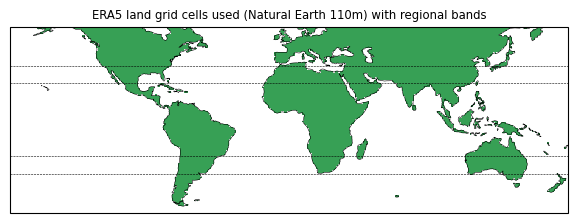

In [6]:
# Land only

import xarray as xr
import numpy as np
import regionmask

# 📌 Settings
BASE_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Temperature/era5_t2m_reg_combined_19712000.nc"
PRES_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Temperature/era5_t2m_reg_combined_19812010.nc"
PLOT_MASK = True   # save a map of the land domain used (for Methods / reviewer)
MASK_FIG = "era5_t2m_land_mask_domain.png"

# 📌 Step 1: Annual means
def extract_annual_with_leap(ds):
    return ds.groupby("valid_time.year").mean(dim="valid_time", skipna=True)

# 📌 Step 2: Load ERA5 datasets
ds_baseline = xr.open_dataset(BASE_PATH)
ds_present = xr.open_dataset(PRES_PATH)

# 📌 Step 3: Annual means
base_annual = extract_annual_with_leap(ds_baseline).sel(year=slice(1971, 2000))
present_annual = extract_annual_with_leap(ds_present).sel(year=slice(1981, 2010))

# 📌 Step 4: Land mask (Natural Earth 110m, same as CMIP6 analysis)
# regionmask returns 0 over land, NaN elsewhere; handles 0–360 or -180–180 lon
land_regions = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask = land_regions.mask(ds_baseline["lon"], ds_baseline["lat"])
is_land = land_mask.notnull()  # boolean (lat, lon)

base_annual_land = base_annual.where(is_land)
present_annual_land = present_annual.where(is_land)

# 📌 Step 5: Regions
regions = {
    "Global": {"lat_min": -60, "lat_max": 60},
    "Tropics": {"lat_min": -23.5, "lat_max": 23.5},
    "Subtropics_N": {"lat_min": 23.5, "lat_max": 35},
    "Subtropics_S": {"lat_min": -35, "lat_max": -23.5},
    "Mid_Latitudes_N": {"lat_min": 35, "lat_max": 60},
    "Mid_Latitudes_S": {"lat_min": -60, "lat_max": -35},
}

# 📌 Step 6: Latitude direction
latitudes = ds_baseline["lat"].values
lat_descending = latitudes[0] > latitudes[-1]

def sel_lat(da, lat_min, lat_max):
    return da.sel(lat=slice(lat_max, lat_min) if lat_descending else slice(lat_min, lat_max))

# 📌 Step 7: Land-only area-weighted mean
# Weights = cos(lat) on land grid cells, 0 over ocean, applied jointly over (lat, lon)
# so the denominator only counts land area (avoids the ocean-dilution issue).
def weighted_mean_land(data, land):
    w = np.cos(np.deg2rad(data["lat"])) * land.astype(float)
    w = w.broadcast_like(data.isel(year=0, drop=True))
    return data.weighted(w).mean(dim=("lat", "lon"), skipna=True)

# 📌 Step 8: Compute stats once per region
results = {}
for region, b in regions.items():
    base_reg = sel_lat(base_annual_land["t2m"], b["lat_min"], b["lat_max"])
    pres_reg = sel_lat(present_annual_land["t2m"], b["lat_min"], b["lat_max"])
    land_reg = sel_lat(is_land, b["lat_min"], b["lat_max"])

    base_c = weighted_mean_land(base_reg, land_reg) - 273.15
    pres_c = weighted_mean_land(pres_reg, land_reg) - 273.15

    results[region] = {
        "base_mean": base_c.mean("year").item(),
        "pres_mean": pres_c.mean("year").item(),
        "base_std": base_c.std("year").item(),
        "pres_std": pres_c.std("year").item(),
        "n_base": base_c.sizes["year"],
        "n_pres": pres_c.sizes["year"],
        "n_land_cells": int(land_reg.sum()),
    }

# 📌 Step 9: Print changes
print("\nAnnual Land-Only Temperature Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):")
print("Region\t\tDiff (°C)\tChange (%)\tStd Dev (°C)\tStd Dev (%)\tLand cells")

for region, r in results.items():
    pooled_std = np.sqrt(((r["n_base"] - 1) * r["base_std"]**2 + (r["n_pres"] - 1) * r["pres_std"]**2)
                         / (r["n_base"] + r["n_pres"] - 2))
    diff = r["pres_mean"] - r["base_mean"]
    base_K = r["base_mean"] + 273.15
    percent_change = diff / base_K * 100
    std_dev_percent = pooled_std / base_K * 100

    print(f"{region:<16} {diff:>8.3f} °C\t{percent_change:>8.2f}%\t\t{pooled_std:>8.3f} °C\t{std_dev_percent:>8.2f}%\t\t{r['n_land_cells']}")

# 📌 Step 10: Detailed per-period stats
print("\n" + "=" * 80)
print("Detailed Land-Only Statistics by Period:")
print("=" * 80)
for region, r in results.items():
    print(f"\n{region}:")
    print(f"  Baseline (1971-2000): Mean = {r['base_mean']:.3f} °C, Std Dev = {r['base_std']:.3f} °C")
    print(f"  Present  (1981-2010): Mean = {r['pres_mean']:.3f} °C, Std Dev = {r['pres_std']:.3f} °C")

# 📌 Step 11 (optional): Map of the land domain used
if PLOT_MASK:
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    plt.rcParams.update({"font.family": "Liberation Sans", "font.size": 7})
    fig = plt.figure(figsize=(183 / 25.4, 90 / 25.4))
    ax = plt.axes(projection=ccrs.PlateCarree())
    is_land.where(is_land).sel(lat=slice(60, -60) if lat_descending else slice(-60, 60)).plot(
        ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, cmap="Greens", vmin=0, vmax=1.5)
    ax.coastlines(linewidth=0.4)
    for lat in [-60, -35, -23.5, 23.5, 35, 60]:
        ax.axhline(lat, color="k", lw=0.4, ls="--")
    ax.set_extent([-180, 180, -60, 60], crs=ccrs.PlateCarree())
    ax.set_title("ERA5 land grid cells used (Natural Earth 110m) with regional bands")
    fig.savefig(MASK_FIG, dpi=600, bbox_inches="tight")
    print(f"\nSaved land-mask domain map → {MASK_FIG}")

# Precipitable Water

In [7]:
# Land only
import xarray as xr
import numpy as np
import regionmask

# 📌 Settings
BASE_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Precipitable_Water/era5_prw_reg_combined_19712000.nc"
PRES_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Precipitable_Water/era5_prw_reg_combined_19812010.nc"
VAR = "tcwv"       # total column water vapour (kg m-2 ≡ mm)
PLOT_MASK = False  # True to save a map of the land domain used
MASK_FIG = "era5_prw_land_mask_domain.png"

# 📌 Step 1: Annual means
def extract_annual_with_leap(ds):
    return ds.groupby("valid_time.year").mean(dim="valid_time", skipna=True)

# 📌 Step 2: Load ERA5 datasets
ds_baseline = xr.open_dataset(BASE_PATH)
ds_present = xr.open_dataset(PRES_PATH)

# 📌 Step 3: Annual means
base_annual = extract_annual_with_leap(ds_baseline).sel(year=slice(1971, 2000))
present_annual = extract_annual_with_leap(ds_present).sel(year=slice(1981, 2010))

# 📌 Step 4: Land mask (Natural Earth 110m, same as CMIP6 analysis)
land_regions = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask = land_regions.mask(ds_baseline["lon"], ds_baseline["lat"])
is_land = land_mask.notnull()  # boolean (lat, lon)

base_annual_land = base_annual.where(is_land)
present_annual_land = present_annual.where(is_land)

# 📌 Step 5: Regions
regions = {
    "Global": {"lat_min": -60, "lat_max": 60},
    "Tropics": {"lat_min": -23.5, "lat_max": 23.5},
    "Subtropics_N": {"lat_min": 23.5, "lat_max": 35},
    "Subtropics_S": {"lat_min": -35, "lat_max": -23.5},
    "Mid_Latitudes_N": {"lat_min": 35, "lat_max": 60},
    "Mid_Latitudes_S": {"lat_min": -60, "lat_max": -35},
}

# 📌 Step 6: Latitude direction
latitudes = ds_baseline["lat"].values
lat_descending = latitudes[0] > latitudes[-1]

def sel_lat(da, lat_min, lat_max):
    return da.sel(lat=slice(lat_max, lat_min) if lat_descending else slice(lat_min, lat_max))

# 📌 Step 7: Land-only area-weighted mean
# Weights = cos(lat) on land, 0 over ocean, applied jointly over (lat, lon)
# so the denominator only counts land area.
def weighted_mean_land(data, land):
    w = np.cos(np.deg2rad(data["lat"])) * land.astype(float)
    w = w.broadcast_like(data.isel(year=0, drop=True))
    return data.weighted(w).mean(dim=("lat", "lon"), skipna=True)

# 📌 Step 8: Compute stats once per region
results = {}
for region, b in regions.items():
    base_reg = sel_lat(base_annual_land[VAR], b["lat_min"], b["lat_max"])
    pres_reg = sel_lat(present_annual_land[VAR], b["lat_min"], b["lat_max"])
    land_reg = sel_lat(is_land, b["lat_min"], b["lat_max"])

    base_sm = weighted_mean_land(base_reg, land_reg)
    pres_sm = weighted_mean_land(pres_reg, land_reg)

    results[region] = {
        "base_mean": base_sm.mean("year").item(),
        "pres_mean": pres_sm.mean("year").item(),
        "base_std": base_sm.std("year").item(),
        "pres_std": pres_sm.std("year").item(),
        "n_base": base_sm.sizes["year"],
        "n_pres": pres_sm.sizes["year"],
        "n_land_cells": int(land_reg.sum()),
    }

# 📌 Step 9: Print changes
print("\nAnnual Land-Only Precipitable Water Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):")
print("Region\t\tDiff (mm)\tChange (%)\tStd Dev (mm)\tStd Dev (%)\tLand cells")

for region, r in results.items():
    pooled_std = np.sqrt(((r["n_base"] - 1) * r["base_std"]**2 + (r["n_pres"] - 1) * r["pres_std"]**2)
                         / (r["n_base"] + r["n_pres"] - 2))
    diff = r["pres_mean"] - r["base_mean"]
    percent_change = diff / r["base_mean"] * 100
    std_dev_percent = pooled_std / r["base_mean"] * 100

    print(f"{region:<16} {diff:>8.3f} mm\t{percent_change:>8.2f}%\t\t{pooled_std:>8.3f} mm\t{std_dev_percent:>8.2f}%\t\t{r['n_land_cells']}")

# 📌 Step 10: Detailed per-period stats
print("\n" + "=" * 80)
print("Detailed Land-Only Statistics by Period:")
print("=" * 80)
for region, r in results.items():
    print(f"\n{region}:")
    print(f"  Baseline (1971-2000): Mean = {r['base_mean']:.3f} mm, Std Dev = {r['base_std']:.3f} mm")
    print(f"  Present  (1981-2010): Mean = {r['pres_mean']:.3f} mm, Std Dev = {r['pres_std']:.3f} mm")

# 📌 Step 11 (optional): Map of the land domain used
if PLOT_MASK:
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    plt.rcParams.update({"font.family": "Liberation Sans", "font.size": 7})
    fig = plt.figure(figsize=(183 / 25.4, 90 / 25.4))
    ax = plt.axes(projection=ccrs.PlateCarree())
    is_land.where(is_land).sel(lat=slice(60, -60) if lat_descending else slice(-60, 60)).plot(
        ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, cmap="Greens", vmin=0, vmax=1.5)
    ax.coastlines(linewidth=0.4)
    for lat in [-60, -35, -23.5, 23.5, 35, 60]:
        ax.axhline(lat, color="k", lw=0.4, ls="--")
    ax.set_extent([-180, 180, -60, 60], crs=ccrs.PlateCarree())
    ax.set_title("ERA5 land grid cells used (Natural Earth 110m) with regional bands")
    fig.savefig(MASK_FIG, dpi=600, bbox_inches="tight")
    print(f"\nSaved land-mask domain map → {MASK_FIG}")


Annual Land-Only Precipitable Water Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):
Region		Diff (mm)	Change (%)	Std Dev (mm)	Std Dev (%)	Land cells
Global              0.093 mm	    0.41%		   0.302 mm	    1.34%		11751
Tropics             0.114 mm	    0.34%		   0.468 mm	    1.40%		4178
Subtropics_N        0.093 mm	    0.53%		   0.310 mm	    1.75%		1768
Subtropics_S       -0.014 mm	   -0.08%		   0.464 mm	    2.43%		818
Mid_Latitudes_N     0.096 mm	    0.80%		   0.231 mm	    1.93%		4886
Mid_Latitudes_S    -0.045 mm	   -0.33%		   0.259 mm	    1.91%		288

Detailed Land-Only Statistics by Period:

Global:
  Baseline (1971-2000): Mean = 22.463 mm, Std Dev = 0.310 mm
  Present  (1981-2010): Mean = 22.556 mm, Std Dev = 0.294 mm

Tropics:
  Baseline (1971-2000): Mean = 33.350 mm, Std Dev = 0.484 mm
  Present  (1981-2010): Mean = 33.465 mm, Std Dev = 0.451 mm

Subtropics_N:
  Baseline (1971-2000): Mean = 17.721 mm, Std Dev = 0.307 mm
  Present  (1981-2010): Mean = 17.

# Precipitation

In [8]:
# Land only

import xarray as xr
import numpy as np
import regionmask

# 📌 Settings
BASE_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Precipitation/era5_pr_reg_combined_19712000.nc"
PRES_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Precipitation/era5_pr_reg_combined_19812010.nc"
VAR = "tp"         # total precipitation (m/day → converted to mm/day)
PLOT_MASK = False  # True to save a map of the land domain used
MASK_FIG = "era5_pr_land_mask_domain.png"

# 📌 Step 1: Annual means
def extract_annual_with_leap(ds):
    return ds.groupby("valid_time.year").mean(dim="valid_time", skipna=True)

# 📌 Step 2: Load ERA5 datasets
ds_baseline = xr.open_dataset(BASE_PATH)
ds_present = xr.open_dataset(PRES_PATH)

# 📌 Step 3: Annual means
base_annual = extract_annual_with_leap(ds_baseline).sel(year=slice(1971, 2000))
present_annual = extract_annual_with_leap(ds_present).sel(year=slice(1981, 2010))

# 📌 Conversion: m/day to mm/day
base_annual[VAR] = base_annual[VAR] * 1000
present_annual[VAR] = present_annual[VAR] * 1000

# 📌 Step 4: Land mask (Natural Earth 110m, same as CMIP6 analysis)
land_regions = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask = land_regions.mask(ds_baseline["lon"], ds_baseline["lat"])
is_land = land_mask.notnull()  # boolean (lat, lon)

base_annual_land = base_annual.where(is_land)
present_annual_land = present_annual.where(is_land)

# 📌 Step 5: Regions
regions = {
    "Global": {"lat_min": -60, "lat_max": 60},
    "Tropics": {"lat_min": -23.5, "lat_max": 23.5},
    "Subtropics_N": {"lat_min": 23.5, "lat_max": 35},
    "Subtropics_S": {"lat_min": -35, "lat_max": -23.5},
    "Mid_Latitudes_N": {"lat_min": 35, "lat_max": 60},
    "Mid_Latitudes_S": {"lat_min": -60, "lat_max": -35},
}

# 📌 Step 6: Latitude direction
latitudes = ds_baseline["lat"].values
lat_descending = latitudes[0] > latitudes[-1]

def sel_lat(da, lat_min, lat_max):
    return da.sel(lat=slice(lat_max, lat_min) if lat_descending else slice(lat_min, lat_max))

# 📌 Step 7: Land-only area-weighted mean
# Weights = cos(lat) on land, 0 over ocean, applied jointly over (lat, lon)
# so the denominator only counts land area.
def weighted_mean_land(data, land):
    w = np.cos(np.deg2rad(data["lat"])) * land.astype(float)
    w = w.broadcast_like(data.isel(year=0, drop=True))
    return data.weighted(w).mean(dim=("lat", "lon"), skipna=True)

# 📌 Step 8: Compute stats once per region
results = {}
for region, b in regions.items():
    base_reg = sel_lat(base_annual_land[VAR], b["lat_min"], b["lat_max"])
    pres_reg = sel_lat(present_annual_land[VAR], b["lat_min"], b["lat_max"])
    land_reg = sel_lat(is_land, b["lat_min"], b["lat_max"])

    base_sm = weighted_mean_land(base_reg, land_reg)
    pres_sm = weighted_mean_land(pres_reg, land_reg)

    results[region] = {
        "base_mean": base_sm.mean("year").item(),
        "pres_mean": pres_sm.mean("year").item(),
        "base_std": base_sm.std("year").item(),
        "pres_std": pres_sm.std("year").item(),
        "n_base": base_sm.sizes["year"],
        "n_pres": pres_sm.sizes["year"],
        "n_land_cells": int(land_reg.sum()),
    }

# 📌 Step 9: Print changes
print("\nAnnual Land-Only Precipitation Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):")
print("Region\t\tDiff (mm/day)\tChange (%)\tStd Dev (mm/day)\tStd Dev (%)\tLand cells")

for region, r in results.items():
    pooled_std = np.sqrt(((r["n_base"] - 1) * r["base_std"]**2 + (r["n_pres"] - 1) * r["pres_std"]**2)
                         / (r["n_base"] + r["n_pres"] - 2))
    diff = r["pres_mean"] - r["base_mean"]
    percent_change = diff / r["base_mean"] * 100
    std_dev_percent = pooled_std / r["base_mean"] * 100

    print(f"{region:<16} {diff:>8.3f} mm/day\t{percent_change:>8.2f}%\t\t{pooled_std:>8.3f} mm/day\t{std_dev_percent:>8.2f}%\t\t{r['n_land_cells']}")

# 📌 Step 10: Detailed per-period stats
print("\n" + "=" * 85)
print("Detailed Land-Only Statistics by Period:")
print("=" * 85)
for region, r in results.items():
    print(f"\n{region}:")
    print(f"  Baseline (1971-2000): Mean = {r['base_mean']:.3f} mm/day, Std Dev = {r['base_std']:.3f} mm/day")
    print(f"  Present  (1981-2010): Mean = {r['pres_mean']:.3f} mm/day, Std Dev = {r['pres_std']:.3f} mm/day")

# 📌 Step 11 (optional): Map of the land domain used
if PLOT_MASK:
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    plt.rcParams.update({"font.family": "Liberation Sans", "font.size": 7})
    fig = plt.figure(figsize=(183 / 25.4, 90 / 25.4))
    ax = plt.axes(projection=ccrs.PlateCarree())
    is_land.where(is_land).sel(lat=slice(60, -60) if lat_descending else slice(-60, 60)).plot(
        ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, cmap="Greens", vmin=0, vmax=1.5)
    ax.coastlines(linewidth=0.4)
    for lat in [-60, -35, -23.5, 23.5, 35, 60]:
        ax.axhline(lat, color="k", lw=0.4, ls="--")
    ax.set_extent([-180, 180, -60, 60], crs=ccrs.PlateCarree())
    ax.set_title("ERA5 land grid cells used (Natural Earth 110m) with regional bands")
    fig.savefig(MASK_FIG, dpi=600, bbox_inches="tight")
    print(f"\nSaved land-mask domain map → {MASK_FIG}")

# 📌 Step 12: Close datasets to avoid file descriptor warnings
ds_baseline.close()
ds_present.close()


Annual Land-Only Precipitation Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):
Region		Diff (mm/day)	Change (%)	Std Dev (mm/day)	Std Dev (%)	Land cells
Global             -0.044 mm/day	   -1.67%		   0.056 mm/day	    2.08%		11751
Tropics            -0.072 mm/day	   -1.94%		   0.117 mm/day	    3.15%		4178
Subtropics_N       -0.032 mm/day	   -1.75%		   0.086 mm/day	    4.72%		1768
Subtropics_S       -0.047 mm/day	   -2.60%		   0.145 mm/day	    8.08%		818
Mid_Latitudes_N    -0.017 mm/day	   -0.89%		   0.044 mm/day	    2.38%		4886
Mid_Latitudes_S    -0.008 mm/day	   -0.25%		   0.113 mm/day	    3.75%		288

Detailed Land-Only Statistics by Period:

Global:
  Baseline (1971-2000): Mean = 2.664 mm/day, Std Dev = 0.040 mm/day
  Present  (1981-2010): Mean = 2.620 mm/day, Std Dev = 0.067 mm/day

Tropics:
  Baseline (1971-2000): Mean = 3.718 mm/day, Std Dev = 0.107 mm/day
  Present  (1981-2010): Mean = 3.646 mm/day, Std Dev = 0.126 mm/day

Subtropics_N:
  Baseline (1971

# Evapotranspiration

In [3]:
# Land only

import xarray as xr
import numpy as np
import regionmask

# 📌 Settings
BASE_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Evaporation/era5_e_reg_combined_19712000.nc"
PRES_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Evaporation/era5_e_reg_combined_19812010.nc"
VAR = "e"          # ERA5 evaporation (m/day of water equivalent → converted to mm/day)
FLIP_SIGN = True   # ERA5 'e' is negative for evaporation (downward-positive convention);
                   # True makes ET positive, matching the CMIP6 hfls-derived ET sign
PLOT_MASK = False  # True to save a map of the land domain used
MASK_FIG = "era5_e_land_mask_domain.png"

# 📌 Step 1: Annual means
def extract_annual_with_leap(ds):
    return ds.groupby("valid_time.year").mean(dim="valid_time", skipna=True)

# 📌 Step 2: Load ERA5 datasets
ds_baseline = xr.open_dataset(BASE_PATH)
ds_present = xr.open_dataset(PRES_PATH)

# 📌 Step 3: Annual means
base_annual = extract_annual_with_leap(ds_baseline).sel(year=slice(1971, 2000))
present_annual = extract_annual_with_leap(ds_present).sel(year=slice(1981, 2010))

# 📌 Conversion: m/day to mm/day (and optional sign flip)
sign = -1 if FLIP_SIGN else 1
base_annual[VAR] = base_annual[VAR] * 1000 * sign
present_annual[VAR] = present_annual[VAR] * 1000 * sign

# 📌 Step 4: Land mask (Natural Earth 110m, same as CMIP6 analysis)
land_regions = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask = land_regions.mask(ds_baseline["lon"], ds_baseline["lat"])
is_land = land_mask.notnull()  # boolean (lat, lon)

base_annual_land = base_annual.where(is_land)
present_annual_land = present_annual.where(is_land)

# 📌 Step 5: Regions
regions = {
    "Global": {"lat_min": -60, "lat_max": 60},
    "Tropics": {"lat_min": -23.5, "lat_max": 23.5},
    "Subtropics_N": {"lat_min": 23.5, "lat_max": 35},
    "Subtropics_S": {"lat_min": -35, "lat_max": -23.5},
    "Mid_Latitudes_N": {"lat_min": 35, "lat_max": 60},
    "Mid_Latitudes_S": {"lat_min": -60, "lat_max": -35},
}

# 📌 Step 6: Latitude direction
latitudes = ds_baseline["lat"].values
lat_descending = latitudes[0] > latitudes[-1]

def sel_lat(da, lat_min, lat_max):
    return da.sel(lat=slice(lat_max, lat_min) if lat_descending else slice(lat_min, lat_max))

# 📌 Step 7: Land-only area-weighted mean
# Weights = cos(lat) on land, 0 over ocean, applied jointly over (lat, lon)
# so the denominator only counts land area.
def weighted_mean_land(data, land):
    w = np.cos(np.deg2rad(data["lat"])) * land.astype(float)
    w = w.broadcast_like(data.isel(year=0, drop=True))
    return data.weighted(w).mean(dim=("lat", "lon"), skipna=True)

# 📌 Step 8: Compute stats once per region
results = {}
for region, b in regions.items():
    base_reg = sel_lat(base_annual_land[VAR], b["lat_min"], b["lat_max"])
    pres_reg = sel_lat(present_annual_land[VAR], b["lat_min"], b["lat_max"])
    land_reg = sel_lat(is_land, b["lat_min"], b["lat_max"])

    base_sm = weighted_mean_land(base_reg, land_reg)
    pres_sm = weighted_mean_land(pres_reg, land_reg)

    results[region] = {
        "base_mean": base_sm.mean("year").item(),
        "pres_mean": pres_sm.mean("year").item(),
        "base_std": base_sm.std("year").item(),
        "pres_std": pres_sm.std("year").item(),
        "n_base": base_sm.sizes["year"],
        "n_pres": pres_sm.sizes["year"],
        "n_land_cells": int(land_reg.sum()),
    }

# 📌 Step 9: Print changes
print("\nAnnual Land-Only Evapotranspiration (ET) Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):")
print(f"Sign convention: {'positive = upward flux (ET)' if FLIP_SIGN else 'ERA5 native (negative = evaporation)'}")
print("Region\t\tDiff (mm/day)\tChange (%)\tStd Dev (mm/day)\tStd Dev (%)\tLand cells")

for region, r in results.items():
    pooled_std = np.sqrt(((r["n_base"] - 1) * r["base_std"]**2 + (r["n_pres"] - 1) * r["pres_std"]**2)
                         / (r["n_base"] + r["n_pres"] - 2))
    diff = r["pres_mean"] - r["base_mean"]
    percent_change = diff / r["base_mean"] * 100
    std_dev_percent = pooled_std / abs(r["base_mean"]) * 100

    print(f"{region:<16} {diff:>8.3f} mm/day\t{percent_change:>8.2f}%\t\t{pooled_std:>8.3f} mm/day\t{std_dev_percent:>8.2f}%\t\t{r['n_land_cells']}")

# 📌 Step 10: Detailed per-period stats
print("\n" + "=" * 85)
print("Detailed Land-Only Statistics by Period:")
print("=" * 85)
for region, r in results.items():
    print(f"\n{region}:")
    print(f"  Baseline (1971-2000): Mean = {r['base_mean']:.3f} mm/day, Std Dev = {r['base_std']:.3f} mm/day")
    print(f"  Present  (1981-2010): Mean = {r['pres_mean']:.3f} mm/day, Std Dev = {r['pres_std']:.3f} mm/day")

# 📌 Step 11 (optional): Map of the land domain used
if PLOT_MASK:
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    plt.rcParams.update({"font.family": "Liberation Sans", "font.size": 7})
    fig = plt.figure(figsize=(183 / 25.4, 90 / 25.4))
    ax = plt.axes(projection=ccrs.PlateCarree())
    is_land.where(is_land).sel(lat=slice(60, -60) if lat_descending else slice(-60, 60)).plot(
        ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, cmap="Greens", vmin=0, vmax=1.5)
    ax.coastlines(linewidth=0.4)
    for lat in [-60, -35, -23.5, 23.5, 35, 60]:
        ax.axhline(lat, color="k", lw=0.4, ls="--")
    ax.set_extent([-180, 180, -60, 60], crs=ccrs.PlateCarree())
    ax.set_title("ERA5 land grid cells used (Natural Earth 110m) with regional bands")
    fig.savefig(MASK_FIG, dpi=600, bbox_inches="tight")
    print(f"\nSaved land-mask domain map → {MASK_FIG}")

# 📌 Step 12: Close datasets to avoid file descriptor warnings
ds_baseline.close()
ds_present.close()

# 📌 Sanity check: overall land-only mean of the baseline (mm/day, after sign handling)
print(f"\nBaseline land-only grid mean (unweighted): {base_annual_land[VAR].mean().item():.4f} mm/day")


Annual Land-Only Evapotranspiration (ET) Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):
Sign convention: positive = upward flux (ET)
Region		Diff (mm/day)	Change (%)	Std Dev (mm/day)	Std Dev (%)	Land cells
Global             -0.002 mm/day	   -0.09%		   0.017 mm/day	    0.97%		11751
Tropics            -0.008 mm/day	   -0.32%		   0.022 mm/day	    0.94%		4178
Subtropics_N       -0.004 mm/day	   -0.30%		   0.019 mm/day	    1.61%		1768
Subtropics_S       -0.030 mm/day	   -1.83%		   0.071 mm/day	    4.37%		818
Mid_Latitudes_N     0.013 mm/day	    1.07%		   0.022 mm/day	    1.79%		4886
Mid_Latitudes_S    -0.009 mm/day	   -0.55%		   0.044 mm/day	    2.63%		288

Detailed Land-Only Statistics by Period:

Global:
  Baseline (1971-2000): Mean = 1.738 mm/day, Std Dev = 0.017 mm/day
  Present  (1981-2010): Mean = 1.737 mm/day, Std Dev = 0.017 mm/day

Tropics:
  Baseline (1971-2000): Mean = 2.369 mm/day, Std Dev = 0.022 mm/day
  Present  (1981-2010): Mean = 2.361 mm/day,

# Soil Moisture

In [11]:
# Land only

import xarray as xr
import numpy as np
import regionmask

# 📌 Settings
BASE_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Soil_Moisture/era5_SM_reg_combined_19712000.nc"
PRES_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Soil_Moisture/era5_SM_reg_combined_19812010.nc"
VAR = "swvl1"      # volumetric soil water, layer 1 (m³/m³)
PLOT_MASK = False  # True to save a map of the land domain used
MASK_FIG = "era5_sm_land_mask_domain.png"

# 📌 Step 1: Annual means
def extract_annual_with_leap(ds):
    return ds.groupby("valid_time.year").mean(dim="valid_time", skipna=True)

# 📌 Step 2: Load ERA5 datasets
ds_baseline = xr.open_dataset(BASE_PATH)
ds_present = xr.open_dataset(PRES_PATH)

# 📌 Step 3: Annual means
base_annual = extract_annual_with_leap(ds_baseline).sel(year=slice(1971, 2000))
present_annual = extract_annual_with_leap(ds_present).sel(year=slice(1981, 2010))

# 📌 Step 4: Land mask (Natural Earth 110m, same as CMIP6 analysis)
land_regions = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask = land_regions.mask(ds_baseline["lon"], ds_baseline["lat"])
is_land = land_mask.notnull()  # boolean (lat, lon)

base_annual_land = base_annual.where(is_land)
present_annual_land = present_annual.where(is_land)

# 📌 Step 5: Regions
regions = {
    "Global": {"lat_min": -60, "lat_max": 60},
    "Tropics": {"lat_min": -23.5, "lat_max": 23.5},
    "Subtropics_N": {"lat_min": 23.5, "lat_max": 35},
    "Subtropics_S": {"lat_min": -35, "lat_max": -23.5},
    "Mid_Latitudes_N": {"lat_min": 35, "lat_max": 60},
    "Mid_Latitudes_S": {"lat_min": -60, "lat_max": -35},
}

# 📌 Step 6: Latitude direction
latitudes = ds_baseline["lat"].values
lat_descending = latitudes[0] > latitudes[-1]

def sel_lat(da, lat_min, lat_max):
    return da.sel(lat=slice(lat_max, lat_min) if lat_descending else slice(lat_min, lat_max))

# 📌 Step 7: Land-only area-weighted mean
# Weights = cos(lat) on land, 0 over ocean, applied jointly over (lat, lon)
# so the denominator only counts land area. Any land cell where swvl1 is NaN
# (e.g. coastal mismatch with ERA5's own land-sea mask) is also dropped from
# the denominator by xarray's weighted mean.
def weighted_mean_land(data, land):
    w = np.cos(np.deg2rad(data["lat"])) * land.astype(float)
    w = w.broadcast_like(data.isel(year=0, drop=True))
    return data.weighted(w).mean(dim=("lat", "lon"), skipna=True)

# 📌 Step 8: Compute stats once per region
results = {}
for region, b in regions.items():
    base_reg = sel_lat(base_annual_land[VAR], b["lat_min"], b["lat_max"])
    pres_reg = sel_lat(present_annual_land[VAR], b["lat_min"], b["lat_max"])
    land_reg = sel_lat(is_land, b["lat_min"], b["lat_max"])

    base_sm = weighted_mean_land(base_reg, land_reg)
    pres_sm = weighted_mean_land(pres_reg, land_reg)

    results[region] = {
        "base_mean": base_sm.mean("year").item(),
        "pres_mean": pres_sm.mean("year").item(),
        "base_std": base_sm.std("year").item(),
        "pres_std": pres_sm.std("year").item(),
        "n_base": base_sm.sizes["year"],
        "n_pres": pres_sm.sizes["year"],
        "n_land_cells": int(land_reg.sum()),
        "n_valid_cells": int(base_reg.isel(year=0).notnull().sum()),
    }

# 📌 Step 9: Print changes
print("\nAnnual Land-Only Soil Moisture Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):")
print("Region\t\tDiff (m³/m³)\tChange (%)\tStd Dev (m³/m³)\tStd Dev (%)\tLand cells (valid)")

for region, r in results.items():
    pooled_std = np.sqrt(((r["n_base"] - 1) * r["base_std"]**2 + (r["n_pres"] - 1) * r["pres_std"]**2)
                         / (r["n_base"] + r["n_pres"] - 2))
    diff = r["pres_mean"] - r["base_mean"]
    percent_change = diff / r["base_mean"] * 100
    std_dev_percent = pooled_std / r["base_mean"] * 100

    print(f"{region:<16} {diff:>8.6f} m³/m³\t{percent_change:>8.2f}%\t\t{pooled_std:>8.6f} m³/m³\t{std_dev_percent:>8.2f}%\t\t"
          f"{r['n_land_cells']} ({r['n_valid_cells']})")

# 📌 Step 10: Detailed per-period stats
print("\n" + "=" * 85)
print("Detailed Land-Only Statistics by Period:")
print("=" * 85)
for region, r in results.items():
    print(f"\n{region}:")
    print(f"  Baseline (1971-2000): Mean = {r['base_mean']:.6f} m³/m³, Std Dev = {r['base_std']:.6f} m³/m³")
    print(f"  Present  (1981-2010): Mean = {r['pres_mean']:.6f} m³/m³, Std Dev = {r['pres_std']:.6f} m³/m³")

# 📌 Step 11 (optional): Map of the land domain used
if PLOT_MASK:
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    plt.rcParams.update({"font.family": "Liberation Sans", "font.size": 7})
    fig = plt.figure(figsize=(183 / 25.4, 90 / 25.4))
    ax = plt.axes(projection=ccrs.PlateCarree())
    is_land.where(is_land).sel(lat=slice(60, -60) if lat_descending else slice(-60, 60)).plot(
        ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, cmap="Greens", vmin=0, vmax=1.5)
    ax.coastlines(linewidth=0.4)
    for lat in [-60, -35, -23.5, 23.5, 35, 60]:
        ax.axhline(lat, color="k", lw=0.4, ls="--")
    ax.set_extent([-180, 180, -60, 60], crs=ccrs.PlateCarree())
    ax.set_title("ERA5 land grid cells used (Natural Earth 110m) with regional bands")
    fig.savefig(MASK_FIG, dpi=600, bbox_inches="tight")
    print(f"\nSaved land-mask domain map → {MASK_FIG}")

# 📌 Step 12: Close datasets to avoid file descriptor warnings
ds_baseline.close()
ds_present.close()


Annual Land-Only Soil Moisture Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):
Region		Diff (m³/m³)	Change (%)	Std Dev (m³/m³)	Std Dev (%)	Land cells (valid)
Global           -0.002590 m³/m³	   -1.07%		0.002513 m³/m³	    1.03%		11751 (11751)
Tropics          -0.002754 m³/m³	   -1.09%		0.002985 m³/m³	    1.18%		4178 (4178)
Subtropics_N     -0.002129 m³/m³	   -1.26%		0.003314 m³/m³	    1.96%		1768 (1768)
Subtropics_S     -0.002869 m³/m³	   -1.56%		0.006990 m³/m³	    3.79%		818 (818)
Mid_Latitudes_N  -0.002632 m³/m³	   -0.95%		0.003569 m³/m³	    1.28%		4886 (4886)
Mid_Latitudes_S  -0.002485 m³/m³	   -1.01%		0.007093 m³/m³	    2.89%		288 (288)

Detailed Land-Only Statistics by Period:

Global:
  Baseline (1971-2000): Mean = 0.243001 m³/m³, Std Dev = 0.001574 m³/m³
  Present  (1981-2010): Mean = 0.240411 m³/m³, Std Dev = 0.003186 m³/m³

Tropics:
  Baseline (1971-2000): Mean = 0.253162 m³/m³, Std Dev = 0.002598 m³/m³
  Present  (1981-2010): Mean = 0.250407 m³/m³,

# Runoff

In [12]:
# Land only

import xarray as xr
import numpy as np
import regionmask

# 📌 Settings
BASE_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Runoff/era5_q_reg_combined_19712000.nc"
PRES_PATH = "/Users/dianindrawati/Documents/ERA5_datasets/Runoff/era5_q_reg_combined_19812010.nc"
VAR = "ro"         # total runoff (m/day → converted to mm/day)
PLOT_MASK = False  # True to save a map of the land domain used
MASK_FIG = "era5_ro_land_mask_domain.png"

# 📌 Step 1: Annual means
def extract_annual_with_leap(ds):
    return ds.groupby("valid_time.year").mean(dim="valid_time", skipna=True)

# 📌 Step 2: Load ERA5 datasets
ds_baseline = xr.open_dataset(BASE_PATH)
ds_present = xr.open_dataset(PRES_PATH)

# 📌 Step 3: Annual means
base_annual = extract_annual_with_leap(ds_baseline).sel(year=slice(1971, 2000))
present_annual = extract_annual_with_leap(ds_present).sel(year=slice(1981, 2010))

# 📌 Conversion: m/day to mm/day
base_annual[VAR] = base_annual[VAR] * 1000
present_annual[VAR] = present_annual[VAR] * 1000

# 📌 Step 4: Land mask (Natural Earth 110m, same as CMIP6 analysis)
land_regions = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask = land_regions.mask(ds_baseline["lon"], ds_baseline["lat"])
is_land = land_mask.notnull()  # boolean (lat, lon)

base_annual_land = base_annual.where(is_land)
present_annual_land = present_annual.where(is_land)

# 📌 Step 5: Regions
regions = {
    "Global": {"lat_min": -60, "lat_max": 60},
    "Tropics": {"lat_min": -23.5, "lat_max": 23.5},
    "Subtropics_N": {"lat_min": 23.5, "lat_max": 35},
    "Subtropics_S": {"lat_min": -35, "lat_max": -23.5},
    "Mid_Latitudes_N": {"lat_min": 35, "lat_max": 60},
    "Mid_Latitudes_S": {"lat_min": -60, "lat_max": -35},
}

# 📌 Step 6: Latitude direction
latitudes = ds_baseline["lat"].values
lat_descending = latitudes[0] > latitudes[-1]

def sel_lat(da, lat_min, lat_max):
    return da.sel(lat=slice(lat_max, lat_min) if lat_descending else slice(lat_min, lat_max))

# 📌 Step 7: Land-only area-weighted mean
# Weights = cos(lat) on land, 0 over ocean, applied jointly over (lat, lon)
# so the denominator only counts land area. Land cells where ro is NaN
# (coastal mismatch with ERA5's own land-sea mask) are also dropped from
# the denominator by xarray's weighted mean.
def weighted_mean_land(data, land):
    w = np.cos(np.deg2rad(data["lat"])) * land.astype(float)
    w = w.broadcast_like(data.isel(year=0, drop=True))
    return data.weighted(w).mean(dim=("lat", "lon"), skipna=True)

# 📌 Step 8: Compute stats once per region
results = {}
for region, b in regions.items():
    base_reg = sel_lat(base_annual_land[VAR], b["lat_min"], b["lat_max"])
    pres_reg = sel_lat(present_annual_land[VAR], b["lat_min"], b["lat_max"])
    land_reg = sel_lat(is_land, b["lat_min"], b["lat_max"])

    base_sm = weighted_mean_land(base_reg, land_reg)
    pres_sm = weighted_mean_land(pres_reg, land_reg)

    results[region] = {
        "base_mean": base_sm.mean("year").item(),
        "pres_mean": pres_sm.mean("year").item(),
        "base_std": base_sm.std("year").item(),
        "pres_std": pres_sm.std("year").item(),
        "n_base": base_sm.sizes["year"],
        "n_pres": pres_sm.sizes["year"],
        "n_land_cells": int(land_reg.sum()),
        "n_valid_cells": int(base_reg.isel(year=0).notnull().sum()),
    }

# 📌 Step 9: Print changes
print("\nAnnual Land-Only Runoff Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):")
print("Region\t\tDiff (mm/day)\tChange (%)\tStd Dev (mm/day)\tStd Dev (%)\tLand cells (valid)")

for region, r in results.items():
    pooled_std = np.sqrt(((r["n_base"] - 1) * r["base_std"]**2 + (r["n_pres"] - 1) * r["pres_std"]**2)
                         / (r["n_base"] + r["n_pres"] - 2))
    diff = r["pres_mean"] - r["base_mean"]
    percent_change = diff / r["base_mean"] * 100
    std_dev_percent = pooled_std / r["base_mean"] * 100

    print(f"{region:<16} {diff:>8.3f} mm/day\t{percent_change:>8.2f}%\t\t{pooled_std:>8.3f} mm/day\t{std_dev_percent:>8.2f}%\t\t"
          f"{r['n_land_cells']} ({r['n_valid_cells']})")

# 📌 Step 10: Detailed per-period stats
print("\n" + "=" * 85)
print("Detailed Land-Only Statistics by Period:")
print("=" * 85)
for region, r in results.items():
    print(f"\n{region}:")
    print(f"  Baseline (1971-2000): Mean = {r['base_mean']:.3f} mm/day, Std Dev = {r['base_std']:.3f} mm/day")
    print(f"  Present  (1981-2010): Mean = {r['pres_mean']:.3f} mm/day, Std Dev = {r['pres_std']:.3f} mm/day")

# 📌 Step 11 (optional): Map of the land domain used
if PLOT_MASK:
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    plt.rcParams.update({"font.family": "Liberation Sans", "font.size": 7})
    fig = plt.figure(figsize=(183 / 25.4, 90 / 25.4))
    ax = plt.axes(projection=ccrs.PlateCarree())
    is_land.where(is_land).sel(lat=slice(60, -60) if lat_descending else slice(-60, 60)).plot(
        ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, cmap="Greens", vmin=0, vmax=1.5)
    ax.coastlines(linewidth=0.4)
    for lat in [-60, -35, -23.5, 23.5, 35, 60]:
        ax.axhline(lat, color="k", lw=0.4, ls="--")
    ax.set_extent([-180, 180, -60, 60], crs=ccrs.PlateCarree())
    ax.set_title("ERA5 land grid cells used (Natural Earth 110m) with regional bands")
    fig.savefig(MASK_FIG, dpi=600, bbox_inches="tight")
    print(f"\nSaved land-mask domain map → {MASK_FIG}")

# 📌 Step 12: Close datasets to avoid file descriptor warnings
ds_baseline.close()
ds_present.close()


Annual Land-Only Runoff Changes by Region (Present - Baseline) (cos-lat weighted, land cells only):
Region		Diff (mm/day)	Change (%)	Std Dev (mm/day)	Std Dev (%)	Land cells (valid)
Global             -0.046 mm/day	   -4.81%		   0.047 mm/day	    4.85%		11751 (11751)
Tropics            -0.049 mm/day	   -3.32%		   0.087 mm/day	    5.94%		4178 (4178)
Subtropics_N       -0.040 mm/day	   -5.64%		   0.080 mm/day	   11.31%		1768 (1768)
Subtropics_S       -0.010 mm/day	   -3.36%		   0.079 mm/day	   26.60%		818 (818)
Mid_Latitudes_N    -0.055 mm/day	   -9.81%		   0.050 mm/day	    8.88%		4886 (4886)
Mid_Latitudes_S    -0.033 mm/day	   -2.73%		   0.091 mm/day	    7.41%		288 (288)

Detailed Land-Only Statistics by Period:

Global:
  Baseline (1971-2000): Mean = 0.963 mm/day, Std Dev = 0.039 mm/day
  Present  (1981-2010): Mean = 0.917 mm/day, Std Dev = 0.053 mm/day

Tropics:
  Baseline (1971-2000): Mean = 1.460 mm/day, Std Dev = 0.079 mm/day
  Present  (1981-2010): Mean = 1.412 mm/day, Std Dev = 0.